# Bilateral Filter — CUDA Version
**執行環境**: Google Colab (Runtime → Change runtime type → **GPU**)

執行前請先將 `dog_gray.jpg` 放入左側檔案瀏覽器的工作目錄（`/content/`）。

流程:
1. 確認 GPU 環境
2. 安裝 libjpeg-dev
3. 編譯 CUDA kernel
4. 執行：分別以 4×4、16×16、32×32 block size 計時（H2D / Kernel / D2H）
5. 產生計時表格
6. 顯示輸入與輸出圖片對比

In [ ]:
# ── 1. 確認 GPU ──────────────────────────────────────────────────────────
!nvidia-smi

Fri Jun  5 17:37:49 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   38C    P8             11W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
# ── 2. 安裝 libjpeg ───────────────────────────────────────────────────────
!apt-get install -y libjpeg-dev > /dev/null 2>&1
print('libjpeg-dev ready.')

libjpeg-dev ready.


In [ ]:
%%writefile bilateral_cuda.cu
/*
 * bilateral_cuda.cu — CUDA parallel version (Global Memory)
 * Loops over block sizes {4,16,32} and reports H2D / D2H / Kernel / Total
 * time separately for each configuration.
 *
 * Output (one CSV line per block size):
 *   CUDA,<BDxBD>,<h2d_ms>,<d2h_ms>,<kernel_ms>,<total_ms>
 */
#include <stdio.h>
#include <stdlib.h>
#include <math.h>
#include <string.h>
#include <jpeglib.h>
#include <cuda_runtime.h>

#define CUDA_CHECK(call) do {                                          \
    cudaError_t err_ = (call);                                          \
    if (err_ != cudaSuccess) {                                          \
        fprintf(stderr, "CUDA error %s at %s:%d\n",                    \
                cudaGetErrorString(err_), __FILE__, __LINE__);          \
        exit(1);                                                        \
    }                                                                   \
} while (0)

#define N       4096
#define RADIUS  5
#define SIGMA_D 3.0f
#define SIGMA_R 20.0f

static int load_jpg(const char *path, float *dst, int n)
{
    FILE *fp = fopen(path, "rb");
    if (!fp) { fprintf(stderr, "Cannot open %s\n", path); return -1; }
    struct jpeg_decompress_struct cinfo;
    struct jpeg_error_mgr jerr;
    cinfo.err = jpeg_std_error(&jerr);
    jpeg_create_decompress(&cinfo);
    jpeg_stdio_src(&cinfo, fp);
    jpeg_read_header(&cinfo, TRUE);
    cinfo.out_color_space = JCS_GRAYSCALE;
    jpeg_start_decompress(&cinfo);
    if ((int)cinfo.output_width != n || (int)cinfo.output_height != n) {
        fprintf(stderr, "Expected %dx%d, got %dx%d\n",
                n, n, cinfo.output_width, cinfo.output_height);
        jpeg_destroy_decompress(&cinfo); fclose(fp); return -1;
    }
    unsigned char *row = (unsigned char *)malloc((size_t)n);
    for (int y = 0; cinfo.output_scanline < cinfo.output_height; y++) {
        jpeg_read_scanlines(&cinfo, &row, 1);
        for (int x = 0; x < n; x++) dst[(size_t)y * n + x] = (float)row[x];
    }
    free(row);
    jpeg_finish_decompress(&cinfo);
    jpeg_destroy_decompress(&cinfo);
    fclose(fp);
    return 0;
}

static void save_jpg(const char *path, const float *src, int n)
{
    FILE *fp = fopen(path, "wb");
    if (!fp) { fprintf(stderr, "Cannot create %s\n", path); return; }
    struct jpeg_compress_struct cinfo;
    struct jpeg_error_mgr jerr;
    cinfo.err = jpeg_std_error(&jerr);
    jpeg_create_compress(&cinfo);
    jpeg_stdio_dest(&cinfo, fp);
    cinfo.image_width      = (JDIMENSION)n;
    cinfo.image_height     = (JDIMENSION)n;
    cinfo.input_components = 1;
    cinfo.in_color_space   = JCS_GRAYSCALE;
    jpeg_set_defaults(&cinfo);
    jpeg_set_quality(&cinfo, 95, TRUE);
    jpeg_start_compress(&cinfo, TRUE);
    unsigned char *row = (unsigned char *)malloc((size_t)n);
    while (cinfo.next_scanline < cinfo.image_height) {
        int y = (int)cinfo.next_scanline;
        for (int x = 0; x < n; x++) {
            float v = src[(size_t)y * n + x];
            row[x] = (v < 0.5f) ? 0 : (v > 254.5f) ? 255 : (unsigned char)(v + 0.5f);
        }
        jpeg_write_scanlines(&cinfo, &row, 1);
    }
    free(row);
    jpeg_finish_compress(&cinfo);
    jpeg_destroy_compress(&cinfo);
    fclose(fp);
}

__global__ void bilateral_kernel(
    const float * __restrict__ src,
    float       * __restrict__ dst,
    int rows, int cols,
    float inv2sd2, float inv2sr2)
{
    int x = blockIdx.x * blockDim.x + threadIdx.x;
    int y = blockIdx.y * blockDim.y + threadIdx.y;
    if (x >= cols || y >= rows) return;

    float cval  = src[y * cols + x];
    float sum_w = 0.0f, sum_v = 0.0f;

    for (int dy = -RADIUS; dy <= RADIUS; dy++) {
        int ny = y + dy;
        if (ny < 0 || ny >= rows) continue;
        for (int dx = -RADIUS; dx <= RADIUS; dx++) {
            int nx = x + dx;
            if (nx < 0 || nx >= cols) continue;
            float nb   = src[ny * cols + nx];
            float diff = cval - nb;
            float w    = expf(-(float)(dx * dx + dy * dy) * inv2sd2)
                       * expf(-(diff * diff) * inv2sr2);
            sum_w += w;
            sum_v += w * nb;
        }
    }
    dst[y * cols + x] = sum_v / sum_w;
}

int main(void)
{
    const float inv2sd2 = 1.0f / (2.0f * SIGMA_D * SIGMA_D);
    const float inv2sr2 = 1.0f / (2.0f * SIGMA_R * SIGMA_R);
    size_t sz    = (size_t)N * N * sizeof(float);

    float *h_img = (float *)malloc(sz);
    float *h_out = (float *)malloc(sz);
    if (!h_img || !h_out) { fputs("malloc failed\n", stderr); return 1; }

    if (load_jpg("dog_gray.jpg", h_img, N) != 0) return 1;

    float *d_img, *d_out;
    CUDA_CHECK(cudaMalloc((void **)&d_img, sz));
    CUDA_CHECK(cudaMalloc((void **)&d_out, sz));

    /* Warm-up: touch h_out's pages and run one untimed H2D/kernel/D2H pass,
     * so CUDA context init, first-launch overhead and first-touch page faults
     * on h_out are not charged to whichever block size happens to run first. */
    memset(h_out, 0, sz);
    CUDA_CHECK(cudaMemcpy(d_img, h_img, sz, cudaMemcpyHostToDevice));
    bilateral_kernel<<<dim3(N / 16, N / 16), dim3(16, 16)>>>(d_img, d_out, N, N, inv2sd2, inv2sr2);
    CUDA_CHECK(cudaGetLastError());
    CUDA_CHECK(cudaMemcpy(h_out, d_out, sz, cudaMemcpyDeviceToHost));
    CUDA_CHECK(cudaDeviceSynchronize());

    const int block_dims[] = {4, 16, 32};
    const int num_configs  = 3;

    for (int ci = 0; ci < num_configs; ci++) {
        int bd = block_dims[ci];

        /* -- H2D -------------------------------------------------------- */
        cudaEvent_t h2d_s, h2d_e;
        cudaEventCreate(&h2d_s); cudaEventCreate(&h2d_e);
        cudaEventRecord(h2d_s);
        CUDA_CHECK(cudaMemcpy(d_img, h_img, sz, cudaMemcpyHostToDevice));
        cudaEventRecord(h2d_e);
        cudaEventSynchronize(h2d_e);
        float h2d_ms;
        cudaEventElapsedTime(&h2d_ms, h2d_s, h2d_e);
        cudaEventDestroy(h2d_s); cudaEventDestroy(h2d_e);

        /* -- Kernel ----------------------------------------------------- */
        dim3 blockSize(bd, bd);
        dim3 gridSize((N + bd - 1) / bd, (N + bd - 1) / bd);
        cudaEvent_t ker_s, ker_e;
        cudaEventCreate(&ker_s); cudaEventCreate(&ker_e);
        cudaEventRecord(ker_s);
        bilateral_kernel<<<gridSize, blockSize>>>(
            d_img, d_out, N, N, inv2sd2, inv2sr2);
        CUDA_CHECK(cudaGetLastError());
        cudaEventRecord(ker_e);
        CUDA_CHECK(cudaEventSynchronize(ker_e));
        float ker_ms;
        cudaEventElapsedTime(&ker_ms, ker_s, ker_e);
        cudaEventDestroy(ker_s); cudaEventDestroy(ker_e);

        /* -- D2H -------------------------------------------------------- */
        cudaEvent_t d2h_s, d2h_e;
        cudaEventCreate(&d2h_s); cudaEventCreate(&d2h_e);
        cudaEventRecord(d2h_s);
        CUDA_CHECK(cudaMemcpy(h_out, d_out, sz, cudaMemcpyDeviceToHost));
        cudaEventRecord(d2h_e);
        cudaEventSynchronize(d2h_e);
        float d2h_ms;
        cudaEventElapsedTime(&d2h_ms, d2h_s, d2h_e);
        cudaEventDestroy(d2h_s); cudaEventDestroy(d2h_e);

        float total_ms = h2d_ms + ker_ms + d2h_ms;
        printf("CUDA,%dx%d,%.2f,%.2f,%.2f,%.2f\n",
               bd, bd, h2d_ms, d2h_ms, ker_ms, total_ms);

        /* Save output image from the 16x16 run */
        if (bd == 16) {
            save_jpg("out_cuda.jpg", h_out, N);
            printf("Output saved to out_cuda.jpg\n");
        }
    }

    cudaFree(d_img);
    cudaFree(d_out);
    free(h_img);
    free(h_out);
    return 0;
}

Writing bilateral_cuda.cu


In [ ]:
# ── 3. 自動偵測 GPU Compute Capability 並編譯 ─────────────────────────────
import subprocess

result = subprocess.run(
    ['nvidia-smi', '--query-gpu=compute_cap', '--format=csv,noheader'],
    capture_output=True, text=True
)
cc = result.stdout.strip().replace('.', '')
arch_flag = f'-arch=sm_{cc}'
print(f'Detected compute capability: {result.stdout.strip()} → {arch_flag}')

compile_cmd = f'nvcc -O2 {arch_flag} -o bilateral_cuda bilateral_cuda.cu -ljpeg'
print(f'Compiling: {compile_cmd}')
ret = subprocess.run(compile_cmd, shell=True, capture_output=True, text=True)
if ret.returncode != 0:
    print('COMPILE ERROR:', ret.stderr)
else:
    print('Compilation successful.')

Detected compute capability: 7.5 → -arch=sm_75
Compiling: nvcc -O2 -arch=sm_75 -o bilateral_cuda bilateral_cuda.cu -ljpeg
Compilation successful.


In [ ]:
# ── 4. 執行（三種 block size） ────────────────────────────────────────────
import subprocess

ret = subprocess.run('./bilateral_cuda', capture_output=True, text=True)
cuda_output = ret.stdout
print(cuda_output)
if ret.returncode != 0:
    print('RUNTIME ERROR:', ret.stderr)

CUDA,4x4,15.26,43.09,59.54,117.88
CUDA,16x16,14.84,14.46,25.11,54.40
Output saved to out_cuda.jpg
CUDA,32x32,14.50,14.09,25.23,53.81



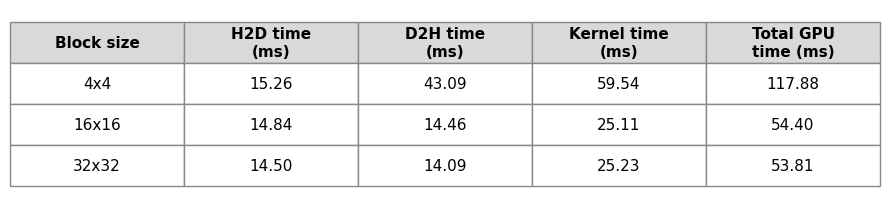

Saved cuda_timing_table.png
Saved results_cuda.csv


In [ ]:
# ── 5. 解析結果 → 計時表格（仿 format.png） ──────────────────────────────
import re
import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np

# Parse CSV lines
rows = []
for line in cuda_output.strip().split('\n'):
    m = re.match(r'CUDA,(\S+),([0-9.]+),([0-9.]+),([0-9.]+),([0-9.]+)', line)
    if m:
        rows.append([
            m.group(1),           # block size
            float(m.group(2)),    # H2D
            float(m.group(3)),    # D2H
            float(m.group(4)),    # Kernel
            float(m.group(5)),    # Total
        ])

if not rows:
    print('No data parsed — check that the binary ran correctly.')
else:
    col_labels = ['Block size', 'H2D time\n(ms)', 'D2H time\n(ms)',
                  'Kernel time\n(ms)', 'Total GPU\ntime (ms)']
    cell_text  = [[r[0]] + [f'{v:.2f}' for v in r[1:]] for r in rows]

    fig, ax = plt.subplots(figsize=(9, 2.2))
    ax.axis('off')

    tbl = ax.table(
        cellText=cell_text,
        colLabels=col_labels,
        cellLoc='center',
        loc='center'
    )
    tbl.auto_set_font_size(False)
    tbl.set_fontsize(11)
    tbl.scale(1, 2.2)

    # Style: grey header, white body
    for (r, c), cell in tbl.get_celld().items():
        cell.set_edgecolor('#888888')
        if r == 0:
            cell.set_facecolor('#d9d9d9')
            cell.set_text_props(fontweight='bold')
        else:
            cell.set_facecolor('white')

    plt.tight_layout()
    plt.savefig('cuda_timing_table.png', dpi=150, bbox_inches='tight')
    plt.show()
    print('Saved cuda_timing_table.png')

    # Also save CSV
    with open('results_cuda.csv', 'w') as f:
        f.write('# paradigm,block_size,h2d_ms,d2h_ms,kernel_ms,total_ms\n')
        for r in rows:
            f.write(f'CUDA,{r[0]},{r[1]:.2f},{r[2]:.2f},{r[3]:.2f},{r[4]:.2f}\n')
    print('Saved results_cuda.csv')

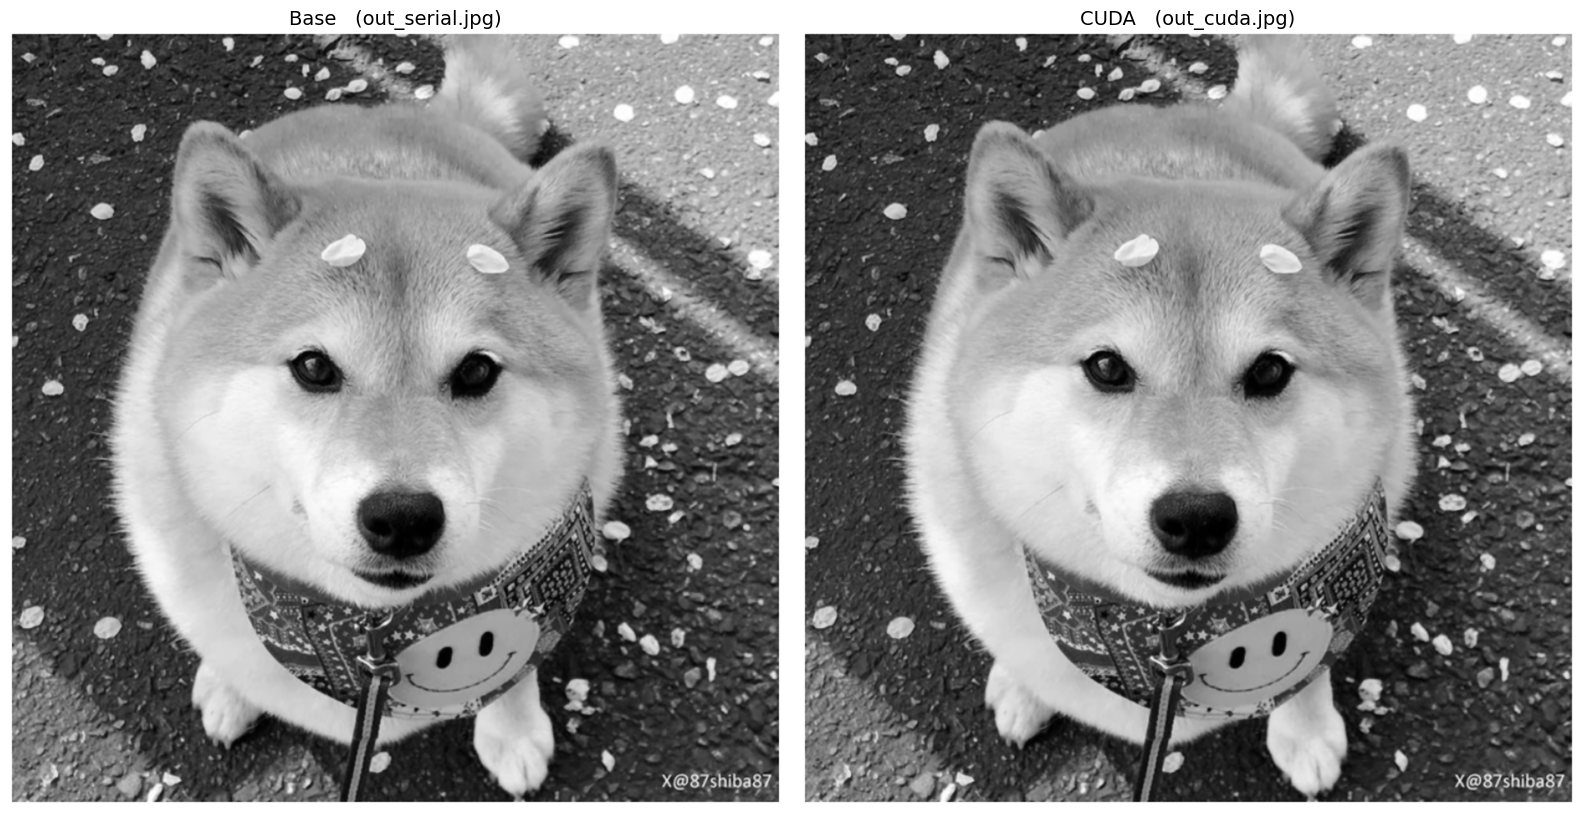

Saved comparison_cuda.png
MSE  : 0.000157
PSNR : 86.1620 dB
MAE  : 0.000157
Saved quality_cuda.txt


In [ ]:
# ── 6. 顯示 base vs CUDA 輸出圖片 ───────────────────────────────────────
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np

img_base = np.array(Image.open('out_serial.jpg').convert('L'), dtype=np.float32)
img_out  = np.array(Image.open('out_cuda.jpg').convert('L'), dtype=np.float32)

diff = img_base - img_out
mse = float(np.mean(diff ** 2))
mae = float(np.mean(np.abs(diff)))
psnr = float('inf') if mse == 0 else float(10.0 * np.log10((255.0 ** 2) / mse))

fig, axes = plt.subplots(1, 2, figsize=(16, 8))
axes[0].imshow(img_base, cmap='gray', vmin=0, vmax=255)
axes[0].set_title('Base   (out_serial.jpg)', fontsize=14)
axes[0].axis('off')
axes[1].imshow(img_out, cmap='gray', vmin=0, vmax=255)
axes[1].set_title('CUDA   (out_cuda.jpg)', fontsize=14)
axes[1].axis('off')
plt.tight_layout()
plt.savefig('comparison_cuda.png', dpi=150, bbox_inches='tight')
plt.show()

print('Saved comparison_cuda.png')
print(f'MSE  : {mse:.6f}')
print(f'PSNR : {psnr:.4f} dB')
print(f'MAE  : {mae:.6f}')

with open('quality_cuda.txt', 'w', encoding='utf-8') as f:
    f.write('Quality report for out_cuda.jpg vs out_serial.jpg\n')
    f.write(f'MSE  : {mse:.6f}\n')
    f.write(f'PSNR : {psnr:.4f} dB\n')
    f.write(f'MAE  : {mae:.6f}\n')
print('Saved quality_cuda.txt')

In [ ]:
# ── 7. 下載輸出檔案 ───────────────────────────────────────────────────────
from google.colab import files

files.download('out_cuda.jpg')
files.download('results_cuda.csv')
files.download('cuda_timing_table.png')
files.download('comparison_cuda.png')
files.download('quality_cuda.txt')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>